# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, brier_score_loss,
    classification_report, precision_recall_curve
)
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "data/raw/diabetes_prediction_dataset.csv"
if not os.path.exists(CSV_PATH) and os.path.exists("../data/raw/diabetes_prediction_dataset.csv"):
    CSV_PATH = "../data/raw/diabetes_prediction_dataset.csv"

df_raw = pd.read_csv(CSV_PATH)
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raw Dataset Shape: 100,000 rows, 9 columns


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


# EDA 1: Schema, Duplicates, Hidden "No Info" & BMI Spike Audit

In [2]:
dup_count = df_raw.duplicated().sum()
print(f"Standard Missing Values (Total) : {df_raw.isnull().sum().sum()}")
print(f"Exact Duplicate Rows            : {dup_count:,} ({dup_count / len(df_raw):.2%}) -> Leaves {len(df_raw) - dup_count:,} unique rows")

print("\n1. Categorical Cardinality & Hidden Missingness Check:")
for col in ["gender", "smoking_history"]:
    print(f"\n--- {col} ---")
    vc = df_raw[col].value_counts()
    pct = (df_raw[col].value_counts(normalize=True) * 100).round(2)
    display(pd.DataFrame({"Count": vc, "Percentage (%)": pct}))

print("\n2. Checking Top 5 Most Frequent BMI Values (Detecting Default Placeholder Spikes):")
display(df_raw["bmi"].value_counts().head(5).to_frame("Record_Count"))

print("\n3. Checking Infant/Pediatric Records (age < 2.0):")
infant_count = (df_raw["age"] < 2.0).sum()
print(f"Records with age < 2.0 years: {infant_count:,} (Min age: {df_raw['age'].min()})")

Standard Missing Values (Total) : 0
Exact Duplicate Rows            : 3,854 (3.85%) -> Leaves 96,146 unique rows

1. Categorical Cardinality & Hidden Missingness Check:

--- gender ---


,Count,Percentage (%)
gender,,
Female,58552,58.55
Male,41430,41.43
Other,18,0.02



--- smoking_history ---


,Count,Percentage (%)
smoking_history,,
No Info,35816,35.82
never,35095,35.10
former,9352,9.35
current,9286,9.29
not current,6447,6.45
ever,4004,4.00



2. Checking Top 5 Most Frequent BMI Values (Detecting Default Placeholder Spikes):


,Record_Count
bmi,
27.32,25495
23.00,103
27.12,101
27.80,100
24.96,100



3. Checking Infant/Pediatric Records (age < 2.0):
Records with age < 2.0 years: 2,101 (Min age: 0.08)


# EDA 2: Class Imbalance, IQR Outliers & Clinical Risk Dashboard

Target Variable ('diabetes') Distribution:


,Count,Percentage (%)
diabetes,,
0,91500,91.5
1,8500,8.5


,count,mean,std,min,50%,max,skewness,IQR_Outliers
age,100000.0,41.89,22.52,0.08,43.00,80.00,-0.05,0
bmi,100000.0,27.32,6.64,10.01,27.32,95.69,1.04,7086
HbA1c_level,100000.0,5.53,1.07,3.50,5.80,9.00,-0.07,1315
blood_glucose_level,100000.0,138.06,40.71,80.00,140.00,300.00,0.82,2038


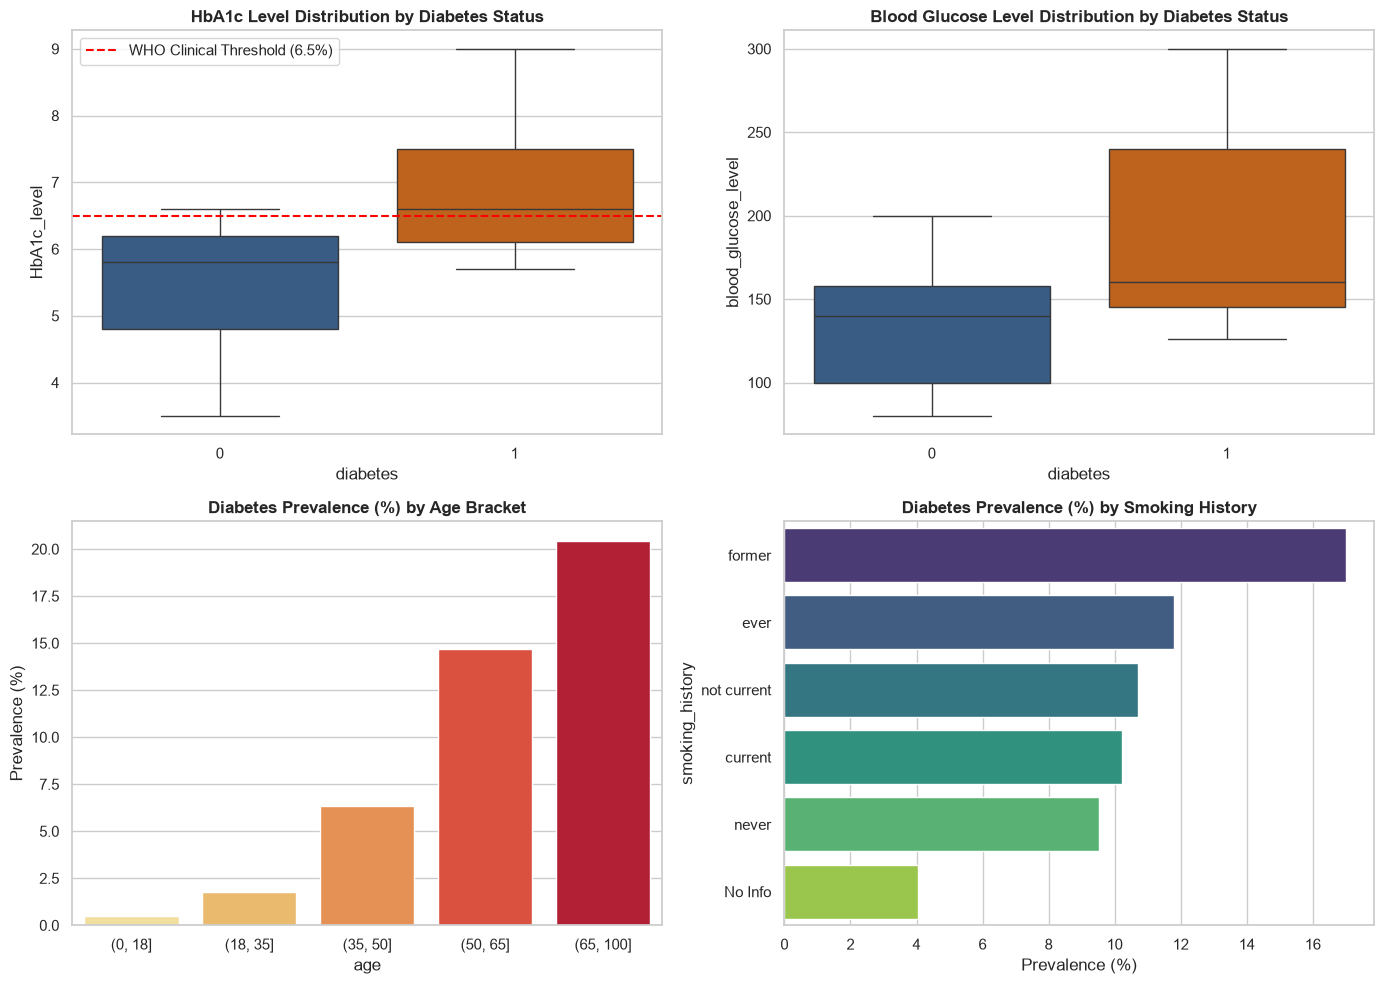

In [3]:
print("Target Variable ('diabetes') Distribution:")
display(pd.DataFrame({
    "Count": df_raw["diabetes"].value_counts(),
    "Percentage (%)": (df_raw["diabetes"].value_counts(normalize=True) * 100).round(2)
}))

num_cols_raw = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
desc = df_raw[num_cols_raw].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc["skewness"] = df_raw[num_cols_raw].skew()

iqr_outliers = []
for col in num_cols_raw:
    s = df_raw[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    iqr_outliers.append(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
desc["IQR_Outliers"] = iqr_outliers
display(desc.round(2))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: HbA1c Level by Diabetes Status
sns.boxplot(data=df_raw, x="diabetes", y="HbA1c_level", palette=["#2b5c8f", "#d95f02"], ax=axes[0, 0])
axes[0, 0].axhline(6.5, color="red", linestyle="--", label="WHO Clinical Threshold (6.5%)")
axes[0, 0].set_title("HbA1c Level Distribution by Diabetes Status", fontweight="bold")
axes[0, 0].legend()

# Plot 2: Blood Glucose Level by Diabetes Status
sns.boxplot(data=df_raw, x="diabetes", y="blood_glucose_level", palette=["#2b5c8f", "#d95f02"], ax=axes[0, 1])
axes[0, 1].set_title("Blood Glucose Level Distribution by Diabetes Status", fontweight="bold")

# Plot 3: Diabetes Prevalence across Age Groups
age_bins = pd.cut(df_raw["age"], bins=[0, 18, 35, 50, 65, 100])
age_risk = df_raw.groupby(age_bins, observed=False)["diabetes"].mean() * 100
sns.barplot(x=age_risk.index.astype(str), y=age_risk.values, palette="YlOrRd", ax=axes[1, 0])
axes[1, 0].set_title("Diabetes Prevalence (%) by Age Bracket", fontweight="bold")
axes[1, 0].set_ylabel("Prevalence (%)")

# Plot 4: Smoking History vs Diabetes Rate (Showing 'No Info' behavior)
smoke_risk = df_raw.groupby("smoking_history")["diabetes"].mean().sort_values(ascending=False) * 100
sns.barplot(x=smoke_risk.values, y=smoke_risk.index, palette="viridis", ax=axes[1, 1])
axes[1, 1].set_title("Diabetes Prevalence (%) by Smoking History", fontweight="bold")
axes[1, 1].set_xlabel("Prevalence (%)")

plt.tight_layout()
plt.savefig("outputs/eda_clinical_diabetes.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop 3,854 exact duplicate rows to prevent identical patient records from leaking across train and test splits.
2. Preserve 'No Info' in smoking_history (~35.8% of records) as an explicit 'Unknown' category rather than dropping it,
   and add a binary indicator 'is_smoking_unknown' so the model distinguishes missing EHR history.
3. Merge the 18 rare 'Other' gender records into the majority category or keep OneHotEncoder(handle_unknown='ignore')
   — here we retain 'Other' cleanly via OneHotEncoder(min_frequency=50) or explicit grouping to avoid sparse noisy splits.
4. Keep high BMI (> 60) and high HbA1c/glucose values since extreme metabolic readings are clinically valid signals.
"""
df_clean = df_raw.drop_duplicates().reset_index(drop=True)

# Consolidate ultra-rare 'Other' gender (18 rows = 0.018%) to avoid unstable OHE columns during stratified splits
df_clean["gender"] = df_clean["gender"].replace({"Other": "Female"})

# Standardize 'No Info' label cleanly
df_clean["smoking_history"] = df_clean["smoking_history"].replace({"No Info": "Unknown"})

print(f"Raw Rows: {len(df_raw):,} -> Cleaned Unique Rows: {len(df_clean):,} | Diabetes Rate: {df_clean['diabetes'].mean():.2%}")

Raw Rows: 100,000 -> Cleaned Unique Rows: 96,146 | Diabetes Rate: 8.82%


# Clinical Feature Engineering & Leak-Free Preprocessing

In [5]:
df_feat = df_clean.copy()

# 1. Explicit EHR data-quality flags discovered during EDA
df_feat["is_smoking_unknown"] = (df_feat["smoking_history"] == "Unknown").astype(int)
df_feat["is_bmi_default_spike"] = (df_feat["bmi"] == 27.32).astype(int)

# 2. Clinical threshold flags (WHO / ADA guidelines: HbA1c >= 6.5%, Prediabetes >= 5.7%)
df_feat["is_hba1c_diabetic_range"] = (df_feat["HbA1c_level"] >= 6.5).astype(int)
df_feat["is_glucose_elevated"] = (df_feat["blood_glucose_level"] >= 140).astype(int)

# 3. Comorbidity burden & metabolic interaction terms
df_feat["comorbidity_count"] = df_feat["hypertension"] + df_feat["heart_disease"]
df_feat["age_bmi_interaction"] = df_feat["age"] * df_feat["bmi"]
df_feat["glycemic_risk_index"] = df_feat["HbA1c_level"] * np.log1p(df_feat["blood_glucose_level"])

X = df_feat.drop(columns=["diabetes"])
y = df_feat["diabetes"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cat_cols = ["gender", "smoking_history"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

print(f"Train Set: {X_train.shape} (Positives: {y_train.sum():,}) | Test Set: {X_test.shape} (Positives: {y_test.sum():,})")

Train Set: (76916, 15) (Positives: 6,786) | Test Set: (19230, 15) (Positives: 1,696)


# Model Benchmarking (Logistic Regression vs. XGBoost) & Clinical Recall Thresholding

In [6]:
def find_optimal_f2_threshold(y_true, y_probs):
    """Optimize F2-Score (weights Recall 2x higher than Precision for medical screening)."""
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    beta = 2.0
    f2_scores = ((1 + beta**2) * precisions * recalls) / ((beta**2 * precisions) + recalls + 1e-8)
    best_idx = np.argmax(f2_scores[:-1])
    return float(thresholds[best_idx])

imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
sqrt_weight = float(np.sqrt(imbalance_ratio))

models = {
    "Logistic Regression (Balanced Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, n_jobs=-1, random_state=42)),
    ]),
    "XGBoost (Clinical Risk Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=sqrt_weight,
            tree_method="hist",
            eval_metric="aucpr",
            n_jobs=-1,
            random_state=42,
        )),
    ]),
}

best_model, best_pr_auc = None, 0.0

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f2_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)
    brier = brier_score_loss(y_test, y_probs)

    print(f"\n---> {name}")
    print(f"PR-AUC : {pr_auc:.4f} | ROC-AUC : {roc_auc:.4f} | Brier Score : {brier:.4f} | Optimal F2 Threshold : {opt_thresh:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Healthy (0)", "Diabetic (1)"]))

    if pr_auc > best_pr_auc:
        best_pr_auc = pr_auc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_diabetes_model.joblib")


---> Logistic Regression (Balanced Baseline)
PR-AUC : 0.8207 | ROC-AUC : 0.9636 | Brier Score : 0.0782 | Optimal F2 Threshold : 0.6437
              precision    recall  f1-score   support

 Healthy (0)       0.98      0.93      0.95     17534
Diabetic (1)       0.53      0.82      0.64      1696

    accuracy                           0.92     19230
   macro avg       0.75      0.87      0.80     19230
weighted avg       0.94      0.92      0.93     19230


---> XGBoost (Clinical Risk Engine)
PR-AUC : 0.8839 | ROC-AUC : 0.9777 | Brier Score : 0.0310 | Optimal F2 Threshold : 0.3582
              precision    recall  f1-score   support

 Healthy (0)       0.99      0.94      0.96     17534
Diabetic (1)       0.59      0.86      0.70      1696

    accuracy                           0.94     19230
   macro avg       0.79      0.90      0.83     19230
weighted avg       0.95      0.94      0.94     19230



['outputs/best_diabetes_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

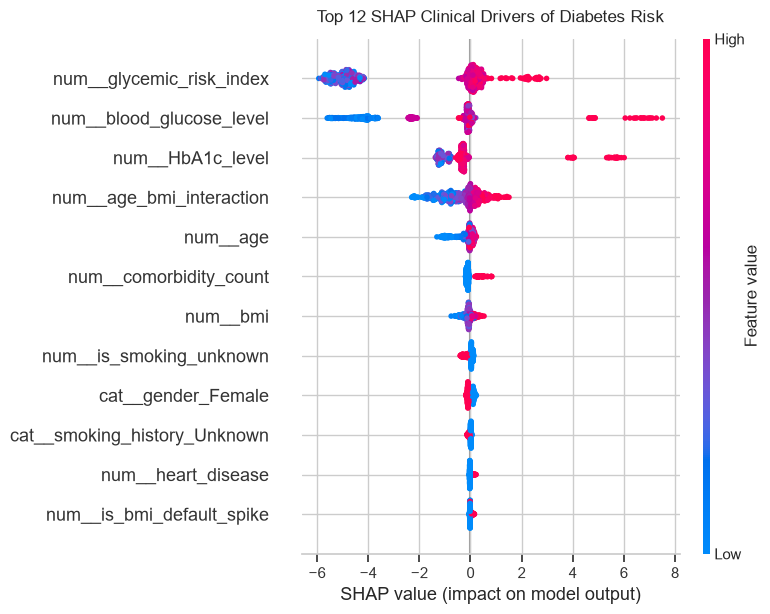

In [7]:
xgb_pipe = models["XGBoost (Clinical Risk Engine)"]

X_test_sample = X_test.sample(800, random_state=42)
X_test_transformed = xgb_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = xgb_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(xgb_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Clinical Drivers of Diabetes Risk", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_clinical_diabetes.png", dpi=150)
plt.show()